In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt 
import seaborn as sns

In [7]:
train_df = pd.read_csv('train.csv')
train_df

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1455,1456,60,RL,62.0,7917,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,8,2007,WD,Normal,175000
1456,1457,20,RL,85.0,13175,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,MnPrv,NaN,0,2,2010,WD,Normal,210000
1457,1458,70,RL,66.0,9042,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,GdPrv,Shed,2500,5,2010,WD,Normal,266500
1458,1459,20,RL,68.0,9717,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,4,2010,WD,Normal,142125


In [8]:
train_df.describe()

,Id,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,...,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,MiscVal,MoSold,YrSold,SalePrice
count,1460.000000,1460.000000,1201.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1452.000000,1460.000000,...,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000
mean,730.500000,56.897260,70.049958,10516.828082,6.099315,5.575342,1971.267808,1984.865753,103.685262,443.639726,...,94.244521,46.660274,21.954110,3.409589,15.060959,2.758904,43.489041,6.321918,2007.815753,180921.195890
std,421.610009,42.300571,24.284752,9981.264932,1.382997,1.112799,30.202904,20.645407,181.066207,456.098091,...,125.338794,66.256028,61.119149,29.317331,55.757415,40.177307,496.123024,2.703626,1.328095,79442.502883
min,1.000000,20.000000,21.000000,1300.000000,1.000000,1.000000,1872.000000,1950.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,2006.000000,34900.000000
25%,365.750000,20.000000,59.000000,7553.500000,5.000000,5.000000,1954.000000,1967.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,5.000000,2007.000000,129975.000000
50%,730.500000,50.000000,69.000000,9478.500000,6.000000,5.000000,1973.000000,1994.000000,0.000000,383.500000,...,0.000000,25.000000,0.000000,0.000000,0.000000,0.000000,0.000000,6.000000,2008.000000,163000.000000
75%,1095.250000,70.000000,80.000000,11601.500000,7.000000,6.000000,2000.000000,2004.000000,166.000000,712.250000,...,168.000000,68.000000,0.000000,0.000000,0.000000,0.000000,0.000000,8.000000,2009.000000,214000.000000
max,1460.000000,190.000000,313.000000,215245.000000,10.000000,9.000000,2010.000000,2010.000000,1600.000000,5644.000000,...,857.000000,547.000000,552.000000,508.000000,480.000000,738.000000,15500.000000,12.000000,2010.000000,755000.000000


In [10]:
X = train_df.drop(columns=['SalePrice'])
y = train_df["SalePrice"].copy()
X = X.drop(columns=['Id'])
X

,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,...,ScreenPorch,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition
0,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,Inside,...,0,0,NaN,NaN,NaN,0,2,2008,WD,Normal
1,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,FR2,...,0,0,NaN,NaN,NaN,0,5,2007,WD,Normal
2,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,Inside,...,0,0,NaN,NaN,NaN,0,9,2008,WD,Normal
3,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,Corner,...,0,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml
4,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,FR2,...,0,0,NaN,NaN,NaN,0,12,2008,WD,Normal
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1455,60,RL,62.0,7917,Pave,NaN,Reg,Lvl,AllPub,Inside,...,0,0,NaN,NaN,NaN,0,8,2007,WD,Normal
1456,20,RL,85.0,13175,Pave,NaN,Reg,Lvl,AllPub,Inside,...,0,0,NaN,MnPrv,NaN,0,2,2010,WD,Normal
1457,70,RL,66.0,9042,Pave,NaN,Reg,Lvl,AllPub,Inside,...,0,0,NaN,GdPrv,Shed,2500,5,2010,WD,Normal
1458,20,RL,68.0,9717,Pave,NaN,Reg,Lvl,AllPub,Inside,...,0,0,NaN,NaN,NaN,0,4,2010,WD,Normal


In [11]:
y

0       208500
1       181500
2       223500
3       140000
4       250000
         ...  
1455    175000
1456    210000
1457    266500
1458    142125
1459    147500
Name: SalePrice, Length: 1460, dtype: int64

In [12]:
test_df = pd.read_csv("test.csv")
test_ids = test_df["Id"].copy()
test_X = test_df.drop(columns=["Id"])

# 缺失值不是真的缺失，而是表示这个类别是无

In [5]:
absence_categorical_cols = [
    "Alley",
    "MasVnrType",
    "BsmtQual",
    "BsmtCond",
    "BsmtExposure",
    "BsmtFinType1",
    "BsmtFinType2",
    "FireplaceQu",
    "GarageType",
    "GarageFinish",
    "GarageQual",
    "GarageCond",
    "PoolQC",
    "Fence",
    "MiscFeature",
]

In [13]:
# 把空值填充为None
for col in absence_categorical_cols:
    if col in X.columns:
        X[col] = X[col].fillna("None")
        test_X[col] = test_X[col].fillna("None")

# 空是指没有该设施， 但是是数值字段，应该填0

In [14]:
absence_numeric_cols = [
    "MasVnrArea",
    "BsmtFinSF1",
    "BsmtFinSF2",
    "BsmtUnfSF",
    "TotalBsmtSF",
    "BsmtFullBath",
    "BsmtHalfBath",
    "GarageCars",
    "GarageArea",
    "BsmtFinSF1",
    "BsmtFinSF2",
]

In [15]:
for col in absence_numeric_cols:
    if col in X.columns:
        X[col] = X[col].fillna(0)
        test_X[col] = test_X[col].fillna(0)

In [ ]:
# 用mean、median、most_frequent, constant自动填充缺失值
from sklearn.impute import SimpleImputer

In [ ]:
# althought it is a numeric column, it is actually a categorical column, so we need to convert it to string type
X["MSSubClass"] = X["MSSubClass"].astype(str)
test_X["MSSubClass"] = test_X["MSSubClass"].astype(str)

# ordinal categorical variable
虽然是str，但是是可比较的，有等级,可以转化为可比较的数字

In [18]:
quality_map = {
    "None": 0,
    "Po": 1,
    "Fa": 2,
    "TA": 3,
    "Gd": 4,
    "Ex": 5,
}

In [19]:
ordinal_maps = {
    "ExterQual": quality_map,
    "ExterCond": quality_map,
    "BsmtQual": quality_map,
    "BsmtCond": quality_map,
    "HeatingQC": quality_map,
    "KitchenQual": quality_map,
    "FireplaceQu": quality_map,
    "GarageQual": quality_map,
    "GarageCond": quality_map,
    "PoolQC": quality_map,

    "BsmtExposure": {
        "None": 0,
        "No": 1,
        "Mn": 2,
        "Av": 3,
        "Gd": 4,
    },

    "BsmtFinType1": {
        "None": 0,
        "Unf": 1,
        "LwQ": 2,
        "Rec": 3,
        "BLQ": 4,
        "ALQ": 5,
        "GLQ": 6,
    },

    "BsmtFinType2": {
        "None": 0,
        "Unf": 1,
        "LwQ": 2,
        "Rec": 3,
        "BLQ": 4,
        "ALQ": 5,
        "GLQ": 6,
    },

    "Functional": {
        "Sal": 0,
        "Sev": 1,
        "Maj2": 2,
        "Maj1": 3,
        "Mod": 4,
        "Min2": 5,
        "Min1": 6,
        "Typ": 7,
    },

    "GarageFinish": {
        "None": 0,
        "Unf": 1,
        "RFn": 2,
        "Fin": 3,
    },

    "PavedDrive": {
        "N": 0,
        "P": 1,
        "Y": 2,
    },

    "LandSlope": {
        "Sev": 0,
        "Mod": 1,
        "Gtl": 2,
    },

    "LotShape": {
        "IR3": 0,
        "IR2": 1,
        "IR1": 2,
        "Reg": 3,
    },
}

In [21]:
# 一一映射
def apply_ordinal_mapping(df, ordinal_maps):
    df = df.copy()

    for col, mapping in ordinal_maps.items():
        if col in df.columns:
            df[col] = df[col].map(mapping)

    return df


X = apply_ordinal_mapping(X, ordinal_maps)
test_X = apply_ordinal_mapping(test_X, ordinal_maps)

In [22]:
X

,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,...,ScreenPorch,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition
0,60,RL,65.0,8450,Pave,None,NaN,Lvl,AllPub,Inside,...,0,0,NaN,None,None,0,2,2008,WD,Normal
1,20,RL,80.0,9600,Pave,None,NaN,Lvl,AllPub,FR2,...,0,0,NaN,None,None,0,5,2007,WD,Normal
2,60,RL,68.0,11250,Pave,None,NaN,Lvl,AllPub,Inside,...,0,0,NaN,None,None,0,9,2008,WD,Normal
3,70,RL,60.0,9550,Pave,None,NaN,Lvl,AllPub,Corner,...,0,0,NaN,None,None,0,2,2006,WD,Abnorml
4,60,RL,84.0,14260,Pave,None,NaN,Lvl,AllPub,FR2,...,0,0,NaN,None,None,0,12,2008,WD,Normal
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1455,60,RL,62.0,7917,Pave,None,NaN,Lvl,AllPub,Inside,...,0,0,NaN,None,None,0,8,2007,WD,Normal
1456,20,RL,85.0,13175,Pave,None,NaN,Lvl,AllPub,Inside,...,0,0,NaN,MnPrv,None,0,2,2010,WD,Normal
1457,70,RL,66.0,9042,Pave,None,NaN,Lvl,AllPub,Inside,...,0,0,NaN,GdPrv,Shed,2500,5,2010,WD,Normal
1458,20,RL,68.0,9717,Pave,None,NaN,Lvl,AllPub,Inside,...,0,0,NaN,None,None,0,4,2010,WD,Normal


# 根据一些经济解释合理构造新variable

In [23]:
# eg.年份不具有可比性，可以构造一些相对指标
def create_time_features(df):
    df = df.copy()

    # 房屋出售时的房龄
    df["HouseAge"] = df["YrSold"] - df["YearBuilt"]

    # 出售时距离上次翻修的年数
    df["RemodAge"] = df["YrSold"] - df["YearRemodAdd"]

    # 车库年龄
    garage_year = df["GarageYrBlt"].fillna(df["YrSold"])
    df["GarageAge"] = df["YrSold"] - garage_year

    # 是否翻修过
    df["IsRemodeled"] = (
        df["YearRemodAdd"] != df["YearBuilt"]
    ).astype(int)

    # 删除原始车库建造年份
    df = df.drop(columns=["GarageYrBlt"])

    return df


X = create_time_features(X)
test_X = create_time_features(test_X)

In [24]:
X

,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,...,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,HouseAge,RemodAge,GarageAge,IsRemodeled
0,60,RL,65.0,8450,Pave,None,NaN,Lvl,AllPub,Inside,...,None,0,2,2008,WD,Normal,5,5,5.0,0
1,20,RL,80.0,9600,Pave,None,NaN,Lvl,AllPub,FR2,...,None,0,5,2007,WD,Normal,31,31,31.0,0
2,60,RL,68.0,11250,Pave,None,NaN,Lvl,AllPub,Inside,...,None,0,9,2008,WD,Normal,7,6,7.0,1
3,70,RL,60.0,9550,Pave,None,NaN,Lvl,AllPub,Corner,...,None,0,2,2006,WD,Abnorml,91,36,8.0,1
4,60,RL,84.0,14260,Pave,None,NaN,Lvl,AllPub,FR2,...,None,0,12,2008,WD,Normal,8,8,8.0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1455,60,RL,62.0,7917,Pave,None,NaN,Lvl,AllPub,Inside,...,None,0,8,2007,WD,Normal,8,7,8.0,1
1456,20,RL,85.0,13175,Pave,None,NaN,Lvl,AllPub,Inside,...,None,0,2,2010,WD,Normal,32,22,32.0,1
1457,70,RL,66.0,9042,Pave,None,NaN,Lvl,AllPub,Inside,...,Shed,2500,5,2010,WD,Normal,69,4,69.0,1
1458,20,RL,68.0,9717,Pave,None,NaN,Lvl,AllPub,Inside,...,None,0,4,2010,WD,Normal,60,14,60.0,1


# 月份转化为相对特征

Cyclical encoding uses sine and cosine functions to map months from a linear scale (1–12) onto a circle, allowing the model to better capture seasonal patterns and cyclical relationships.

In [25]:
def create_month_features(df):
    df = df.copy()

    month_angle = 2 * np.pi * (df["MoSold"] - 1) / 12

    df["MoSold_sin"] = np.sin(month_angle)
    df["MoSold_cos"] = np.cos(month_angle)

    # 删除原始月份
    df = df.drop(columns=["MoSold"])

    return df


X = create_month_features(X)
test_X = create_month_features(test_X)

构造面积和浴室总量

In [27]:
def create_total_features(df):
    df = df.copy()

    area_cols = [
        "TotalBsmtSF",
        "1stFlrSF",
        "2ndFlrSF",
    ]

    for col in area_cols:
        df[col] = df[col].fillna(0)

    df["TotalSF"] = df[area_cols].sum(axis=1)

    # 总浴室数量，半浴室按 0.5 计算
    bath_cols = [
        "BsmtFullBath",
        "BsmtHalfBath",
        "FullBath",
        "HalfBath",
    ]

    for col in bath_cols:
        df[col] = df[col].fillna(0)

    df["TotalBathrooms"] = (
        df["BsmtFullBath"]
        + 0.5 * df["BsmtHalfBath"]
        + df["FullBath"]
        + 0.5 * df["HalfBath"]
    )

    # 总门廊面积
    porch_cols = [
        "OpenPorchSF",
        "3SsnPorch",
        "EnclosedPorch",
        "ScreenPorch",
        "WoodDeckSF",
    ]

    for col in porch_cols:
        df[col] = df[col].fillna(0)

    df["TotalPorchSF"] = df[porch_cols].sum(axis=1)

    return df


X = create_total_features(X)
test_X = create_total_features(test_X)

有些数据可能偏度过大

In [28]:
continuous_cols = [
    "LotFrontage",
    "LotArea",
    "MasVnrArea",
    "BsmtFinSF1",
    "BsmtFinSF2",
    "BsmtUnfSF",
    "TotalBsmtSF",
    "1stFlrSF",
    "2ndFlrSF",
    "LowQualFinSF",
    "GrLivArea",
    "GarageArea",
    "WoodDeckSF",
    "OpenPorchSF",
    "EnclosedPorch",
    "3SsnPorch",
    "ScreenPorch",
    "PoolArea",
    "MiscVal",
    "TotalSF",
    "TotalPorchSF",
]

In [29]:
skewness = X[continuous_cols].skew().abs()
skewed_cols = skewness[skewness > 0.75].index.tolist()

In [30]:
skewed_cols

['LotFrontage',
 'LotArea',
 'MasVnrArea',
 'BsmtFinSF1',
 'BsmtFinSF2',
 'BsmtUnfSF',
 'TotalBsmtSF',
 '1stFlrSF',
 '2ndFlrSF',
 'LowQualFinSF',
 'GrLivArea',
 'WoodDeckSF',
 'OpenPorchSF',
 'EnclosedPorch',
 '3SsnPorch',
 'ScreenPorch',
 'PoolArea',
 'MiscVal',
 'TotalSF',
 'TotalPorchSF']

In [31]:
for col in skewed_cols:
    X[col] = np.log1p(X[col].clip(lower=0))
    test_X[col] = np.log1p(test_X[col].clip(lower=0))

SalePrice右偏吗？处理response variable

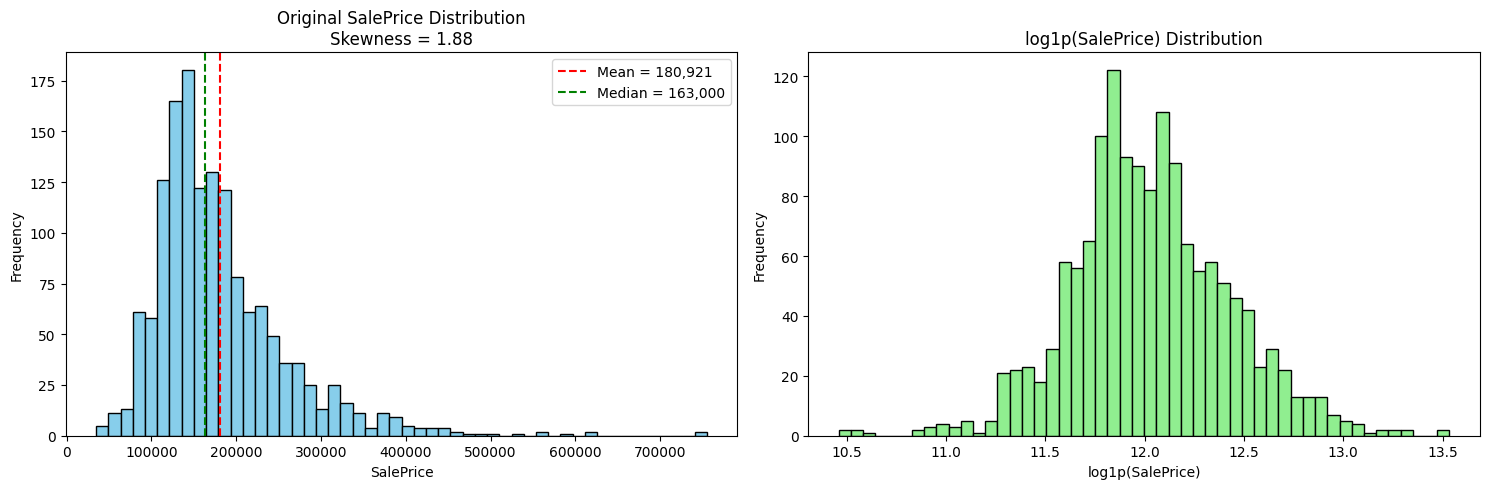

Mean: 180,921.20
Median: 163,000.00
Skewness: 1.8829


In [33]:
sale_price = train_df["SalePrice"].dropna()

# 统计量
mean_price = sale_price.mean()
median_price = sale_price.median()
skewness = sale_price.skew()

# 对数转换
log_sale_price = np.log1p(sale_price)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# 原始房价分布
axes[0].hist(
    sale_price,
    bins=50,
    color="skyblue",
    edgecolor="black"
)

axes[0].axvline(
    mean_price,
    color="red",
    linestyle="--",
    label=f"Mean = {mean_price:,.0f}"
)

axes[0].axvline(
    median_price,
    color="green",
    linestyle="--",
    label=f"Median = {median_price:,.0f}"
)

axes[0].set_title(
    f"Original SalePrice Distribution\nSkewness = {skewness:.2f}"
)
axes[0].set_xlabel("SalePrice")
axes[0].set_ylabel("Frequency")
axes[0].legend()

# log1p 后的房价分布
axes[1].hist(
    log_sale_price,
    bins=50,
    color="lightgreen",
    edgecolor="black"
)

axes[1].set_title("log1p(SalePrice) Distribution")
axes[1].set_xlabel("log1p(SalePrice)")
axes[1].set_ylabel("Frequency")

plt.tight_layout()
plt.show()

print(f"Mean: {mean_price:,.2f}")
print(f"Median: {median_price:,.2f}")
print(f"Skewness: {skewness:.4f}")

In [34]:
y_log = np.log1p(y)

# 普通类别字段独热编码

In [35]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer

In [36]:
categorical_cols = X.select_dtypes(
    include=["object"]
).columns.tolist()

numeric_cols = X.select_dtypes(
    exclude=["object"]
).columns.tolist()

In [37]:
numeric_pipeline = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="median"),
        ),
    ]
)

In [39]:
categorical_pipeline = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="most_frequent"),
        ),
        (
            "onehot",
            OneHotEncoder(
                handle_unknown="ignore"
            ),
        ),
    ]
)

In [40]:
preprocessor = ColumnTransformer(
    transformers=[
        (
            "numeric",
            numeric_pipeline,
            numeric_cols,
        ),
        (
            "categorical",
            categorical_pipeline,
            categorical_cols,
        ),
    ]
)

In [41]:
X_processed = preprocessor.fit_transform(X)
test_processed = preprocessor.transform(test_X)

/Users/corinne_777/Desktop/Kaggle/house-prices-advanced-regression-techniques/.venv-py3.8.7/lib/python3.8/site-packages/sklearn/impute/_base.py:558: UserWarning: Skipping features without any observed values: ['LotShape' 'LandSlope' 'ExterQual' 'ExterCond' 'BsmtQual' 'BsmtCond'
 'BsmtExposure' 'BsmtFinType1' 'BsmtFinType2' 'HeatingQC' 'KitchenQual'
 'Functional' 'FireplaceQu' 'GarageFinish' 'GarageQual' 'GarageCond'
 'PavedDrive' 'PoolQC']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/Users/corinne_777/Desktop/Kaggle/house-prices-advanced-regression-techniques/.venv-py3.8.7/lib/python3.8/site-packages/sklearn/impute/_base.py:558: UserWarning: Skipping features without any observed values: ['LotShape' 'LandSlope' 'ExterQual' 'ExterCond' 'BsmtQual' 'BsmtCond'
 'BsmtExposure' 'BsmtFinType1' 'BsmtFinType2' 'HeatingQC' 'KitchenQual'
 'Functional' 'FireplaceQu' 'GarageFinish' 'GarageQual' 'GarageCond'
 'PavedDrive' 'PoolQC']. At least one 

In [42]:
feature_names = preprocessor.get_feature_names_out()

print("处理前特征数量：", X.shape[1])
print("处理后特征数量：", len(feature_names))

处理前特征数量： 86
处理后特征数量： 233


# 要在训练集里面进一步划分验证集

In [43]:
from sklearn.model_selection import train_test_split
# 随机划分train和valid，不适用于时间序列数据
X_train, X_valid, y_train, y_valid = train_test_split(
    X,
    y_log,
    test_size=0.2,
    random_state=42,
)

In [44]:
numeric_pipeline = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="median"),
        ),
    ]
)

categorical_pipeline = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="most_frequent"),
        ),
        (
            "onehot",
            OneHotEncoder(handle_unknown="ignore"),
        ),
    ]
)

preprocessor = ColumnTransformer(
    transformers=[
        (
            "numeric",
            numeric_pipeline,
            numeric_cols,
        ),
        (
            "categorical",
            categorical_pipeline,
            categorical_cols,
        ),
    ]
)

In [ ]:
X_train_processed = preprocessor.fit_transform(X_train)

X_valid_processed = preprocessor.transform(X_valid)

/Users/corinne_777/Desktop/Kaggle/house-prices-advanced-regression-techniques/.venv-py3.8.7/lib/python3.8/site-packages/sklearn/impute/_base.py:558: UserWarning: Skipping features without any observed values: ['LotShape' 'LandSlope' 'ExterQual' 'ExterCond' 'BsmtQual' 'BsmtCond'
 'BsmtExposure' 'BsmtFinType1' 'BsmtFinType2' 'HeatingQC' 'KitchenQual'
 'Functional' 'FireplaceQu' 'GarageFinish' 'GarageQual' 'GarageCond'
 'PavedDrive' 'PoolQC']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/Users/corinne_777/Desktop/Kaggle/house-prices-advanced-regression-techniques/.venv-py3.8.7/lib/python3.8/site-packages/sklearn/impute/_base.py:558: UserWarning: Skipping features without any observed values: ['LotShape' 'LandSlope' 'ExterQual' 'ExterCond' 'BsmtQual' 'BsmtCond'
 'BsmtExposure' 'BsmtFinType1' 'BsmtFinType2' 'HeatingQC' 'KitchenQual'
 'Functional' 'FireplaceQu' 'GarageFinish' 'GarageQual' 'GarageCond'
 'PavedDrive' 'PoolQC']. At least one 

In [46]:
X_train_processed

<1168x231 sparse matrix of type '<class 'numpy.float64'>'
	with 64437 stored elements in Compressed Sparse Row format>

Ridge

In [47]:
from sklearn.linear_model import Ridge

model = Ridge(alpha=20.0)

model.fit(X_train_processed, y_train)

valid_pred_log = model.predict(X_valid_processed)

# evaluate model:RMSE

In [48]:
from sklearn.metrics import mean_squared_error

rmse_log = np.sqrt(
    mean_squared_error(y_valid, valid_pred_log)
)

print("Validation RMSE:", rmse_log)

Validation RMSE: 0.13351910240455767


# compare models

In [49]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import Ridge, ElasticNet
from sklearn.metrics import mean_squared_error

models = {
    "Ridge": Ridge(alpha=20.0),

    "RandomForest": RandomForestRegressor(
        n_estimators=500,
        max_depth=None,
        min_samples_leaf=1,
        random_state=42,
        n_jobs=-1,
    ),
}

results = {}

for name, model in models.items():
    model.fit(X_train_processed, y_train)

    pred_log = model.predict(X_valid_processed)

    score = np.sqrt(
        mean_squared_error(y_valid, pred_log)
    )

    results[name] = score
    print(f"{name}: {score:.5f}")

Ridge: 0.13352
RandomForest: 0.14772


# cross_validation

如果要k-fold cross-validation，就不能先processed再训练，会有data-leakage

In [51]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import Ridge
from sklearn.model_selection import KFold, cross_val_score

In [52]:
categorical_cols = X.select_dtypes(
    include=["object"]
).columns.tolist()

numeric_cols = X.select_dtypes(
    exclude=["object"]
).columns.tolist()

numeric_pipeline = Pipeline([
    (
        "imputer",
        SimpleImputer(strategy="median"),
    ),
    (
        "scaler",
        StandardScaler(),
    ),
])

categorical_pipeline = Pipeline([
    (
        "imputer",
        SimpleImputer(strategy="most_frequent"),
    ),
    (
        "onehot",
        OneHotEncoder(handle_unknown="ignore"),
    ),
])

In [53]:
preprocessor = ColumnTransformer([
    (
        "numeric",
        numeric_pipeline,
        numeric_cols,
    ),
    (
        "categorical",
        categorical_pipeline,
        categorical_cols,
    ),
])

In [54]:
model_pipeline = Pipeline([
    (
        "preprocessor",
        preprocessor,
    ),
    (
        "model",
        Ridge(alpha=20.0),
    ),
])

In [55]:
cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42,
)

scores = cross_val_score(
    model_pipeline,
    X,
    y_log,
    cv=cv,
    scoring="neg_root_mean_squared_error",
    n_jobs=-1,
)

rmse_scores = -scores

print("每折 RMSE:", rmse_scores)
print("平均 RMSE:", rmse_scores.mean())
print("标准差:", rmse_scores.std())

每折 RMSE: [0.13093735 0.11850944 0.17278357 0.11947221 0.11595563]
平均 RMSE: 0.13153163890647177
标准差: 0.02125885688257387


/Users/corinne_777/Desktop/Kaggle/house-prices-advanced-regression-techniques/.venv-py3.8.7/lib/python3.8/site-packages/sklearn/impute/_base.py:558: UserWarning: Skipping features without any observed values: ['LotShape' 'LandSlope' 'ExterQual' 'ExterCond' 'BsmtQual' 'BsmtCond'
 'BsmtExposure' 'BsmtFinType1' 'BsmtFinType2' 'HeatingQC' 'KitchenQual'
 'Functional' 'FireplaceQu' 'GarageFinish' 'GarageQual' 'GarageCond'
 'PavedDrive' 'PoolQC']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/Users/corinne_777/Desktop/Kaggle/house-prices-advanced-regression-techniques/.venv-py3.8.7/lib/python3.8/site-packages/sklearn/impute/_base.py:558: UserWarning: Skipping features without any observed values: ['LotShape' 'LandSlope' 'ExterQual' 'ExterCond' 'BsmtQual' 'BsmtCond'
 'BsmtExposure' 'BsmtFinType1' 'BsmtFinType2' 'HeatingQC' 'KitchenQual'
 'Functional' 'FireplaceQu' 'GarageFinish' 'GarageQual' 'GarageCond'
 'PavedDrive' 'PoolQC']. At least one 